<a href="https://colab.research.google.com/github/Dharshanthisside/ITA0616---Machine-learning/blob/main/CMP_Linear_and_Polynomial_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

            Position  Level   Salary
0   Business Analyst      1    45000
1  Junior Consultant      2    50000
2  Senior Consultant      3    60000
3            Manager      4    80000
4    Country Manager      5   110000
5     Region Manager      6   150000
6            Partner      7   200000
7     Senior Partner      8   300000
8            C-level      9   500000
9                CEO     10  1000000


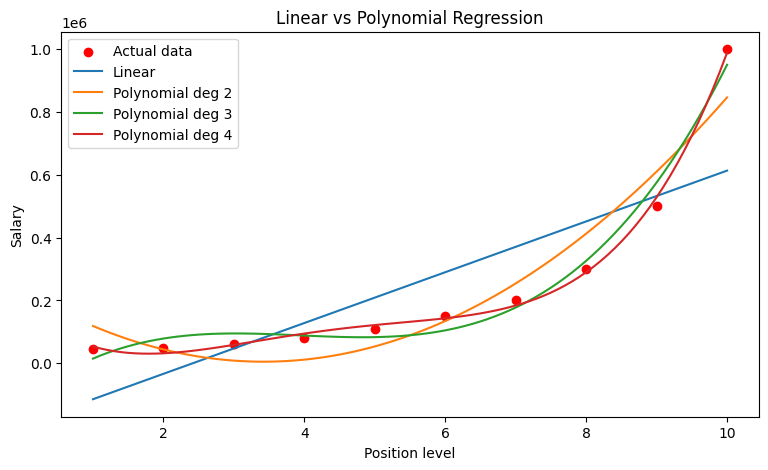

                Model  R2 score        RMSE
0      Linear (deg 1)     0.669  163388.735
1  Polynomial (deg 2)     0.916   82212.124
2  Polynomial (deg 3)     0.981   38931.504
3  Polynomial (deg 4)     0.997   14503.235

Linear prediction for level 6.5     : 330378.79
Polynomial (deg 4) prediction for 6.5: 158862.45


In [1]:
# Program 9: Compare Linear and Polynomial Regression
# Dataset: Position-Salary (Level vs Salary) - classic dataset, embedded below
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error

data = pd.DataFrame({
    "Position": ["Business Analyst","Junior Consultant","Senior Consultant","Manager","Country Manager",
                 "Region Manager","Partner","Senior Partner","C-level","CEO"],
    "Level":  [1,2,3,4,5,6,7,8,9,10],
    "Salary": [45000,50000,60000,80000,110000,150000,200000,300000,500000,1000000]})
print(data)

X = data[["Level"]].values
y = data["Salary"].values

# Linear model
lin = LinearRegression().fit(X, y)
y_lin = lin.predict(X)

# Polynomial models of degree 2, 3, 4
results = [("Linear (deg 1)", r2_score(y, y_lin), np.sqrt(mean_squared_error(y, y_lin)))]
X_grid = np.arange(1, 10.01, 0.1).reshape(-1, 1)
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color="red", label="Actual data")
plt.plot(X_grid, lin.predict(X_grid), label="Linear")

models = {}
for d in (2, 3, 4):
    pf = PolynomialFeatures(degree=d)
    Xp = pf.fit_transform(X)
    m = LinearRegression().fit(Xp, y)
    pred = m.predict(Xp)
    results.append((f"Polynomial (deg {d})", r2_score(y, pred), np.sqrt(mean_squared_error(y, pred))))
    plt.plot(X_grid, m.predict(pf.transform(X_grid)), label=f"Polynomial deg {d}")
    models[d] = (pf, m)

plt.title("Linear vs Polynomial Regression")
plt.xlabel("Position level"); plt.ylabel("Salary"); plt.legend(); plt.show()

print(pd.DataFrame(results, columns=["Model", "R2 score", "RMSE"]).round(3))

# Predict salary for level 6.5
print("\nLinear prediction for level 6.5     :", round(lin.predict([[6.5]])[0], 2))
pf, m = models[4]
print("Polynomial (deg 4) prediction for 6.5:", round(m.predict(pf.transform([[6.5]]))[0], 2))